## Week 10: K-Means and Silohuette Score

This week I will be testing k-means and silohuette score on my two datasets. I will use them to look at customer segmentation for each dataset to see how customers differ.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import roc_curve, auc, silhouette_score
from sklearn.preprocessing import StandardScaler

### Dataset 1: Instacart Dataset

In [2]:
data1 = pd.read_csv('https://raw.githubusercontent.com/eghatzis0527/DX699---HW-Assignments/refs/heads/main/instacart.csv')

transform_cols = ['times_purchased', 'num_orders', 'frequency', 'Product Popularity', 'Last Product Order', 'Last Order', 'Orders Since Last Purchase']

for col in transform_cols:
    data1[f'log_{col}'] = np.log1p(data1[col])

data1_transformed = data1.drop(columns = ['times_purchased', 'num_orders', 'frequency', 'Product Popularity', 'Last Product Order', 'Last Order', 'Orders Since Last Purchase'])

data1_transformed.head()

,user_id,product_id,ordered,log_times_purchased,log_num_orders,log_frequency,log_Product Popularity,log_Last Product Order,log_Last Order,log_Orders Since Last Purchase
0,71,45,0.0,1.791759,3.178054,0.196710,0.005878,2.302585,3.178054,2.708050
1,71,117,1.0,2.995732,3.178054,0.602175,0.001219,3.178054,3.178054,0.000000
2,71,2078,0.0,0.693147,3.178054,0.042560,0.006478,1.386294,3.178054,3.044522
3,71,2825,0.0,1.098612,3.178054,0.083382,0.003743,1.945910,3.178054,2.890372
4,71,3376,1.0,1.098612,3.178054,0.083382,0.003602,2.995732,3.178054,1.609438


In [22]:
X = data1_transformed.drop(columns = ['ordered', 'user_id', 'product_id'])
y = data1_transformed['ordered']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

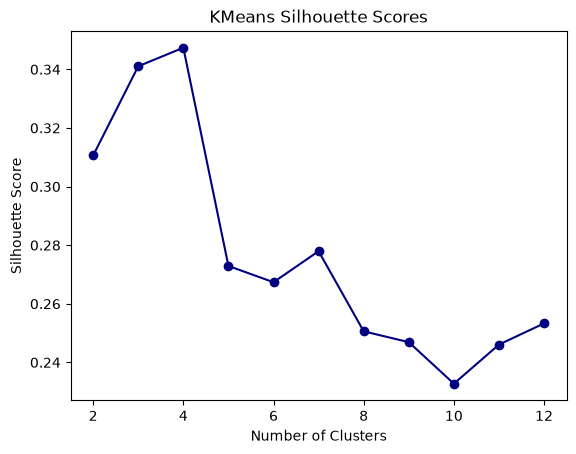

In [23]:
scores = {}

for k in range(2, 13):
    model = KMeans(n_clusters = k, n_init = 10)

    train_clusters = model.fit_predict(X_train_scaled, y_train)

    train_score = silhouette_score(X_train_scaled, train_clusters, sample_size = 2000)

    scores[k] = train_score

pd.Series(scores).sort_values(ascending = False)

plt.plot(list(scores.keys()), list(scores.values()), marker = 'o', color = 'navy')

plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('KMeans Silhouette Scores')
plt.show()

In [24]:
best_model = KMeans(n_clusters = 4, n_init = 10)

train_clusters = best_model.fit_predict(X_train_scaled)

test_clusters = best_model.predict(X_test_scaled)

test_profiles = X_test.copy()

test_profiles['cluster'] = test_clusters
test_profiles['target'] = y_test.to_numpy()

profiles = test_profiles.groupby('cluster').mean()

profile_rates = test_profiles.groupby('cluster')['target'].mean()

print(profile_rates)

cluster
0    0.072790
1    0.019577
2    0.165171
3    0.176471
Name: target, dtype: float64


In [25]:
profiles

,log_times_purchased,log_num_orders,log_frequency,log_Product Popularity,log_Last Product Order,log_Last Order,log_Orders Since Last Purchase,target
cluster,,,,,,,,
0,0.841377,2.134439,0.186170,0.004739,1.643588,2.134439,1.118882,0.072790
1,0.871154,3.570537,0.045106,0.003974,2.798616,3.570537,2.518386,0.019577
2,2.085516,3.399659,0.249143,0.007729,3.275065,3.399659,1.026034,0.165171
3,1.441398,2.724888,0.253018,0.091294,2.387670,2.724888,1.123907,0.176471


### Dataset 2: Amazon Reviews Dataset

In [16]:
import ast
from sklearn.preprocessing import MultiLabelBinarizer

small_reviews = pd.read_csv('https://raw.githubusercontent.com/eghatzis0527/DX699---HW-Assignments/refs/heads/main/small_reviews%5B1%5D.csv')

small_meta = pd.read_csv('https://raw.githubusercontent.com/eghatzis0527/DX699---HW-Assignments/refs/heads/main/small_meta%5B1%5D.csv')

small_meta = small_meta.set_index(keys = 'parent_asin')

small_meta = small_meta.drop(columns = ['title', 'images'])

data2 = small_reviews.join(small_meta, on = 'parent_asin', how = 'inner')

data2 = data2.drop(columns = ['main_category', 'store', 'rating_number', 'videos', 'images', 'subtitle', 'author', 'bought_together', 'features', 'description', 'details', 'timestamp', 'text', 'title'])

data2['product_review_count'] = data2.groupby('asin').transform('size')
data2['user_review_count'] = data2.groupby('user_id').transform('size')

data2['price'] = data2['price'].fillna(data2['price'].median())

data2['categories'] = data2['categories'].apply(ast.literal_eval)

mlb = MultiLabelBinarizer()

categories = pd.DataFrame(mlb.fit_transform(data2['categories']), columns = mlb.classes_, index = data2.index)

top_30 = categories.sum().sort_values(ascending = False).head(31).index

categories = categories[top_30[1:31]]

data2 = data2.drop(columns = 'categories')

data2 = data2.join(categories)

columns_to_transform = ['helpful_vote', 'average_rating', 'price', 'product_review_count', 'user_review_count']

for col in columns_to_transform:
    data2[f'log_{col}'] = np.log1p(data2[col])

data2_transformed = data2.drop(columns = ['helpful_vote', 'average_rating', 'price', 'product_review_count', 'user_review_count'])

data2_transformed = data2_transformed.reset_index(drop = True)

for i in range(len(data2_transformed)):
    if data2_transformed.iloc[i]['rating'] == 4:
        data2_transformed.loc[i, 'liked'] = 1
    elif data2_transformed.iloc[i]['rating'] == 5:
        data2_transformed.loc[i, 'liked'] = 1
    else:
        data2_transformed.loc[i, 'liked'] = 0

X = data2_transformed.drop(columns = ['asin', 'parent_asin', 'user_id', 'liked', 'rating'])
y = data2_transformed['liked']

X.head()

,verified_purchase,Beverages,Snacks & Sweets,Pantry Staples,Coffee,Snack Foods,Candy & Chocolate,"Bottled Beverages, Water & Drink Mixes",Cooking & Baking,Breads & Bakery,...,Whole Coffee Beans,"Canned, Jarred & Packaged Foods",Cold Cereals,"Baking Syrups, Sugars & Sweeteners",Black,log_helpful_vote,log_average_rating,log_price,log_product_review_count,log_user_review_count
0,False,1,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0.000000,1.704748,3.257712,0.693147,0.693147
1,True,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,3.295837,1.686399,3.351307,0.693147,0.693147
2,True,1,0,0,1,0,0,0,0,0,...,1,0,0,0,0,0.000000,1.686399,2.889816,0.693147,1.098612
3,True,0,0,1,0,0,0,0,1,0,...,0,0,0,0,0,0.000000,1.722767,2.771964,0.693147,1.098612
4,True,1,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0.000000,1.686399,3.395179,1.609438,0.693147


In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

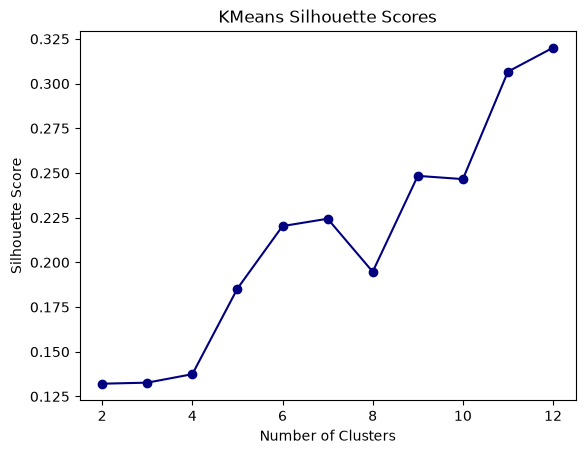

In [18]:
scores = {}

for k in range(2, 13):
    model = KMeans(n_clusters = k, n_init = 10)

    train_clusters = model.fit_predict(X_train_scaled, y_train)

    train_score = silhouette_score(X_train_scaled, train_clusters, sample_size = 2000)

    scores[k] = train_score

pd.Series(scores).sort_values(ascending = False)

plt.plot(list(scores.keys()), list(scores.values()), marker = 'o', color = 'navy')

plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('KMeans Silhouette Scores')
plt.show()

In [19]:
best_model = KMeans(n_clusters = 12, n_init = 10)

train_clusters = best_model.fit_predict(X_train_scaled)

test_clusters = best_model.predict(X_test_scaled)

test_profiles = X_test.copy()

test_profiles['cluster'] = test_clusters
test_profiles['target'] = y_test.to_numpy()

profiles = test_profiles.groupby('cluster').mean()

profile_rates = test_profiles.groupby('cluster')['target'].mean()

print(profile_rates)

cluster
0     0.875000
1     1.000000
2     0.794118
3     0.750000
4     0.500000
5     0.757576
6     0.818182
7     1.000000
8     1.000000
9     1.000000
10    0.952381
11    0.833333
Name: target, dtype: float64


In [21]:
pd.set_option('display.max_columns', None)

profiles

,verified_purchase,Beverages,Snacks & Sweets,Pantry Staples,Coffee,Snack Foods,Candy & Chocolate,"Bottled Beverages, Water & Drink Mixes",Cooking & Baking,Breads & Bakery,Single-Serve Capsules & Pods,Tea,Cookies,Meat Snacks,"Soups, Stocks & Broths",Nuts & Seeds,Jerky,Juices,Ground Coffee,Breakfast Foods,Cereals,Granola,Fruit & Herbal Tea,Herbal,Bars,Roasted Coffee Beans,Whole Coffee Beans,"Canned, Jarred & Packaged Foods",Cold Cereals,"Baking Syrups, Sugars & Sweeteners",Black,log_helpful_vote,log_average_rating,log_price,log_product_review_count,log_user_review_count,target
cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0.875000,1.000000,0.000000,0.0,0.0,0.00000,0.000000,1.0,0.000000,0.0,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.375,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.223970,1.703271,2.743580,0.982523,2.404038,0.875000
1,0.600000,0.000000,0.000000,0.0,0.0,0.00000,0.000000,0.0,0.000000,0.0,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000,0.000000,1.0,1.0,0.2,0.0,0.0,0.0,0.0,0.0,0.000000,0.6,0.0,0.000000,0.000000,1.704341,2.439260,0.936426,2.065594,1.000000
2,0.852941,0.000000,0.000000,1.0,0.0,0.00000,0.000000,0.0,0.235294,0.0,0.00000,0.000000,0.000000,0.000000,0.235294,0.205882,0.0,0.000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.088235,0.0,0.0,0.000000,0.324654,1.701210,2.854444,0.776625,2.234823,0.794118
3,1.000000,0.000000,1.000000,0.0,0.0,1.00000,0.000000,0.0,0.000000,0.0,0.00000,0.000000,0.000000,1.000000,0.000000,0.000000,1.0,0.000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.259930,1.718221,2.394797,0.995693,1.506929,0.750000
4,0.500000,1.000000,0.000000,0.0,0.0,0.00000,0.000000,0.0,0.000000,0.0,0.00000,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000,0.000000,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.833051,1.726949,2.650960,0.794513,2.656269,0.500000
5,0.909091,0.000000,0.969697,0.0,0.0,0.30303,0.666667,0.0,0.000000,0.0,0.00000,0.000000,0.000000,0.030303,0.000000,0.000000,0.0,0.000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.381649,1.686340,2.809458,0.772017,1.712832,0.757576
6,0.909091,0.000000,0.000000,0.0,0.0,0.00000,0.000000,0.0,0.000000,1.0,0.00000,0.000000,0.636364,0.000000,0.000000,0.000000,0.0,0.000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.262761,1.639431,2.874396,0.920922,1.754022,0.818182
7,0.750000,0.416667,0.000000,0.0,0.0,0.00000,0.000000,0.0,0.000000,0.0,0.00000,0.416667,0.000000,0.000000,0.000000,0.000000,0.0,0.000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.166667,0.311472,1.708728,3.100629,0.760725,1.807203,1.000000
8,1.000000,1.000000,0.000000,0.0,1.0,0.00000,0.000000,0.0,0.000000,0.0,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.000000,0.0,0.0,0.000000,0.000000,1.704583,3.817113,0.693147,1.445186,1.000000


## Conclusion

Looking at the results, the first dataset had a steady increase in rates while the second dataset varied across all the clusters. I do not find that super surprising based on how the lift results have looked in the past. Also, looking at the silhouette score for each amount of clusters, I found it interesting how for the second dataset it effectively had a steady increase until the largest number of clusters, but for the first dataset there was a steady increase until 4 and then a sharp decrease.

Looking at the profiles, for dataset 1, the only noticeable thing that the top cluster has compared to others is that the products in that cluster are more popular than the other products in the other clusters. As for dataset 2, there are no noticeable trends between the clusters with the highest rates compared to the other ones. The only thing I noticed was that 3 of the 4 top rated clusters have a value of 0 for log_helpful_votes which I found interesting. 